# EP N°2 — Deep Learning (AVY1103)
## 12 configuraciones de CNN (3 arquitecturas × 4 dimensiones de imagen) + modelo para la API

Mismo diseño experimental del EP1 (3 modelos × 4 dimensiones = 12 combinaciones), ahora con
**redes convolucionales** y con el dataset de rostros del curso + una clase `desconocido`.
Se comparan las 12 configuraciones con evidencia (métricas, curvas, matriz de confusión) y se
elige la ganadora para la API, tal como pide la pauta: *"gráficos que muestren las ventajas de
una combinación modelo-matrices sobre otra"*.

**Dimensiones de entrada comparadas** (las mismas del EP1): `128×128×3`, `128×128×1`, `64×64×3`, `64×64×1`.

**Detalle importante para la app:** el formato que la app envía a la API siempre es **128×128×3**.
Por eso cada configuración recibe siempre esa imagen y hace la conversión (reducir a 64×64
y/o pasar a gris) **dentro del propio modelo**. Así, gane la dimensión que gane, el modelo
guardado acepta lo mismo que envía la app y la API no cambia.

**Plan:**
1. Pipeline de datos (carga, normalización, aumento de datos)
2. Train / Val / Test (60/20/20)
3. Tres arquitecturas de CNN × cuatro dimensiones
4. Entrenamiento de las 12 configuraciones bajo las mismas condiciones
5. Comparación por evidencia (tabla, barras, curvas train vs val) y selección del ganador
6. Evaluación final del ganador en Test (matriz de confusión, reporte, aciertos y errores visuales)
7. Guardar el modelo ganador (para la API)

## 1. Importar librerías

In [1]:
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from PIL import Image

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Versión de TensorFlow:", keras.__version__)


Versión de TensorFlow: 3.13.2


## 2. Preparación del dataset

### Características de las imágenes digitales (IL 2.1)

- Una imagen a color es una **matriz** de forma `(alto, ancho, canales)`,
  con valores de intensidad entre 0 y 255 por canal (R, G, B).
- La **resolución** define el nivel de detalle disponible; los
  **canales de color** multiplican la cantidad de información.
- Una **CNN** aprovecha la estructura espacial 2D de la imagen mediante
  filtros convolucionales — a diferencia de una red densa, que aplana todo
  a un vector y pierde la relación de vecindad entre píxeles.

Usamos el mismo dataset propio del curso (fotos organizadas en carpetas
por alumno), publicado en Kaggle.

In [2]:
from google.colab import files
import os

subido = files.upload()   # elige dataset_total.zip (está en tu carpeta Documents)
!unzip -q -o dataset_total.zip -d dataset_total

DATASET_PATH = "dataset_total"
print("Personas (carpetas):", len(os.listdir(DATASET_PATH)))


Saving dataset_total.zip to dataset_total.zip
Personas (carpetas): 19


In [3]:
ALTO, ANCHO, CANALES = 128, 128, 3
EXTENSIONES = ("*.jpg", "*.jpeg", "*.png")

rutas_imagenes = []
for ext in EXTENSIONES:
    rutas_imagenes.extend(glob.glob(os.path.join(DATASET_PATH, "**", ext), recursive=True))
rutas_imagenes = sorted(rutas_imagenes)

print(f"Total de imágenes encontradas: {len(rutas_imagenes)}")


Total de imágenes encontradas: 200


In [4]:
from PIL import Image, ImageOps

def obtener_etiqueta(ruta):
    '''La etiqueta es el nombre de la carpeta que contiene la imagen (nombre del alumno).'''
    return os.path.basename(os.path.dirname(ruta))

def cargar_imagen(ruta, tamano=(ALTO, ANCHO)):
    with Image.open(ruta) as img:
        img = ImageOps.exif_transpose(img).convert("RGB").resize(tamano, Image.LANCZOS)
        return np.asarray(img, dtype=np.uint8)

x_datos = np.stack([cargar_imagen(r) for r in rutas_imagenes])
etiquetas_texto = [obtener_etiqueta(r) for r in rutas_imagenes]

clases = sorted(set(etiquetas_texto))
num_clases = len(clases)
clase_a_indice = {nombre: i for i, nombre in enumerate(clases)}
y_datos = np.array([clase_a_indice[e] for e in etiquetas_texto])

# Normalización: de [0, 255] a [0, 1]
x_datos = x_datos.astype("float32") / 255.0

print(f"x_datos: shape={x_datos.shape}, dtype={x_datos.dtype}")
print(f"Número de clases (alumnos): {num_clases}")


x_datos: shape=(200, 128, 128, 3), dtype=float32
Número de clases (alumnos): 19


In [5]:
from sklearn.datasets import fetch_lfw_people

# Caras de personas que NO están en el curso (dataset público LFW)
lfw = fetch_lfw_people(min_faces_per_person=20, color=True, resize=1.0,
                       slice_=(slice(0, 250), slice(0, 250)))
imgs = lfw.images
if imgs.max() <= 1.5:
    imgs = imgs * 255.0

rng = np.random.default_rng(SEED)
elegidos = []
for persona in np.unique(lfw.target):                 # máx. 2 fotos por persona
    idxs = np.where(lfw.target == persona)[0]
    elegidos.extend(rng.choice(idxs, size=min(2, len(idxs)), replace=False))
elegidos = rng.permutation(elegidos)[:45]

x_desc = np.stack([
    np.asarray(Image.fromarray(imgs[i].clip(0, 255).astype("uint8")).resize((ANCHO, ALTO), Image.LANCZOS))
    for i in elegidos
]).astype("float32") / 255.0

clases = clases + ["desconocido"]
num_clases = len(clases)
x_datos = np.concatenate([x_datos, x_desc])
y_datos = np.concatenate([y_datos, np.full(len(x_desc), num_clases - 1)])

print(f"Ahora hay {num_clases} clases y {len(x_datos)} imágenes (45 son 'desconocido')")

Ahora hay 20 clases y 245 imágenes (45 son 'desconocido')


## 3. División Train / Validation / Test (60/20/20)

El Test se reserva aparte y no participa del entrenamiento ni de la
selección de arquitectura — se usa una sola vez, al final.

In [6]:
indices = np.arange(len(y_datos))

idx_trainval, idx_test = train_test_split(indices, test_size=0.20, random_state=SEED, stratify=y_datos)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, random_state=SEED, stratify=y_datos[idx_trainval])

x_train, y_train = x_datos[idx_train], y_datos[idx_train]
x_val, y_val = x_datos[idx_val], y_datos[idx_val]
x_test, y_test = x_datos[idx_test], y_datos[idx_test]

print(f"Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")


Train: 147 | Val: 49 | Test: 49


## 4. Pipeline de aumento de datos

Se activa solo durante el entrenamiento (se apaga automáticamente en
`predict`/`evaluate`). Con ~6 fotos de entrenamiento por alumno, generar
variaciones leves en cada época ayuda a no memorizar las fotos exactas.

In [7]:
aumento_datos = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),                       # hasta ±18°
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomBrightness(0.25, value_range=(0, 1)),
    layers.RandomContrast(0.25),
], name="aumento_datos")

## 5. Tres arquitecturas de CNN × cuatro dimensiones

Tres variantes que aíslan el efecto de BatchNorm y Dropout, todas con el mismo número de
bloques convolucionales para que la comparación sea justa:

- **A — Básica:** Conv2D + MaxPooling ×3, sin BatchNorm ni Dropout (línea base).
- **B — Con BatchNorm:** igual que A, + `BatchNormalization()` tras cada convolución
  — estabiliza y suele acelerar el entrenamiento.
- **C — BatchNorm + Dropout:** igual que B, + Dropout entre bloques y antes de la salida.
  Justificación de la regularización: el dataset es muy chico (unas pocas decenas de fotos por
  clase y ~6 de entrenamiento por persona), así que la red tiende a memorizar; el Dropout apaga
  neuronas al azar en cada paso para forzar representaciones más robustas y reducir el
  sobreajuste, y el BatchNorm además aporta un leve efecto regularizador.

**Dimensiones** (igual que el EP1): `128×128×3`, `128×128×1` (gris), `64×64×3`, `64×64×1`.
Los datos se cargan una sola vez a 128×128×3 y cada modelo parte con capas de preprocesado
(`Resizing` y, si corresponde, conversión a gris con pesos de luminancia fijos) — así las 12
configuraciones ven exactamente las mismas fotos y los mismos conjuntos train/val/test.

In [8]:
def capas_dimension(tam, canales):
    '''Capas de preprocesado: parten de 128x128x3 y dejan la imagen en (tam, tam, canales).'''
    capas = []
    if tam != ALTO:
        capas.append(layers.Resizing(tam, tam, interpolation="bilinear", name="reducir"))
    if canales == 1:
        # 1x1 conv fija con pesos de luminancia (R,G,B) -> gris. Sin capas personalizadas,
        # así el .keras se carga en la API sin código extra.
        capas.append(layers.Conv2D(1, 1, use_bias=False, trainable=False, name="gris"))
    return capas


def bloques_cnn(arquitectura, num_clases):
    '''Cuerpo de la CNN según la arquitectura A, B o C.'''
    usa_bn = arquitectura in ("B_batchnorm", "C_batchnorm_dropout")
    usa_do = arquitectura == "C_batchnorm_dropout"
    caps = []
    for filtros, p_drop in [(32, 0.2), (64, 0.2), (128, 0.3)]:
        caps.append(layers.Conv2D(filtros, 3, activation="relu", padding="same"))
        if usa_bn:
            caps.append(layers.BatchNormalization(momentum=0.9))
        caps.append(layers.MaxPooling2D(2))
        if usa_do:
            caps.append(layers.Dropout(p_drop))
    caps += [layers.Flatten(), layers.Dense(128, activation="relu")]
    if usa_do:
        caps.append(layers.Dropout(0.4))
    caps.append(layers.Dense(num_clases, activation="softmax"))
    return caps


def construir_modelo(arquitectura, tam, canales, num_clases):
    '''Modelo completo: entrada 128x128x3 -> aumento -> preprocesado de dimensión -> CNN.'''
    keras.utils.set_random_seed(SEED)          # mismos pesos iniciales para comparar justo
    modelo = keras.Sequential(
        [layers.Input(shape=(ALTO, ANCHO, CANALES)), aumento_datos]
        + capas_dimension(tam, canales)
        + bloques_cnn(arquitectura, num_clases),
        name=f"{arquitectura}__{tam}x{tam}x{canales}",
    )
    if canales == 1:
        peso_gris = np.array([0.299, 0.587, 0.114], dtype="float32").reshape(1, 1, 3, 1)
        modelo.get_layer("gris").set_weights([peso_gris])
    return modelo


ARQUITECTURAS = ["A_basica", "B_batchnorm", "C_batchnorm_dropout"]
DIMENSIONES = [(128, 3), (128, 1), (64, 3), (64, 1)]          # (tamaño, canales)
nombre_dim = lambda tam, canales: f"{tam}x{tam}x{canales}"

input_shape = (ALTO, ANCHO, CANALES)
construir_modelo("C_batchnorm_dropout", 64, 1, num_clases).summary()

Model: "C_batchnorm_dropout__64x64x1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_datos (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reducir (Resizing)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gris (Conv2D)                   │ (None, 64, 64, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,144,855 (4.37 MB)

 Trainable params: 1,144,404 (4.37 MB)

 Non-trainable params: 451 (1.76 KB)

## 6. Hiperparámetros comunes

Mismos para las 12 configuraciones — si no, la comparación no sería justa.

| Parámetro | Valor | Por qué |
|---|---|---|
| Learning rate | `1e-3` | Valor por defecto de Adam |
| Batch size | `8` | Dataset chico (pocas fotos de entrenamiento) |
| Épocas | `30` (con EarlyStopping, paciencia 6) | Techo alto, EarlyStopping corta antes si no mejora y restaura los mejores pesos |
| Semilla | `42` | Mismos pesos iniciales y misma partición train/val/test en todas |

In [9]:
LEARNING_RATE = 1e-3
BATCH_SIZE = 8
EPOCHS = 30


## 7. Entrenamiento de las 12 configuraciones

In [10]:
resultados = []
historiales = {}
modelos_entrenados = {}

for arq in ARQUITECTURAS:
    for tam, canales in DIMENSIONES:
        clave = f"{arq}__{nombre_dim(tam, canales)}"
        print(f"\n=== Entrenando: {clave} ===")

        modelo = construir_modelo(arq, tam, canales, num_clases)
        modelo.compile(
            optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=6, restore_best_weights=True,
        )

        inicio = time.time()
        history = modelo.fit(
            x_train, y_train,
            validation_data=(x_val, y_val),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            callbacks=[early_stop], verbose=0,
        )
        tiempo = time.time() - inicio

        # métricas finales con los mejores pesos (restore_best_weights)
        tr_loss, tr_acc = modelo.evaluate(x_train, y_train, verbose=0)
        va_loss, va_acc = modelo.evaluate(x_val, y_val, verbose=0)

        historiales[clave] = history
        modelos_entrenados[clave] = modelo
        resultados.append({
            "configuracion": clave,
            "arquitectura": arq,
            "dimension": nombre_dim(tam, canales),
            "epocas_corridas": len(history.history["loss"]),
            "train_accuracy": tr_acc, "train_loss": tr_loss,
            "val_accuracy": va_acc, "val_loss": va_loss,
            "n_parametros": modelo.count_params(),
            "tiempo_seg": round(tiempo, 1),
        })
        print(f"  epocas={len(history.history['loss'])} | train_acc={tr_acc:.3f} | "
              f"val_acc={va_acc:.3f} | val_loss={va_loss:.3f} | {tiempo:.0f}s")

print("\n✅ Entrenamiento de las 12 configuraciones finalizado.")


=== Entrenando: A_basica__128x128x3 ===
  epocas=14 | train_acc=0.810 | val_acc=0.735 | val_loss=0.922 | 134s

=== Entrenando: A_basica__128x128x1 ===
  epocas=19 | train_acc=0.939 | val_acc=0.776 | val_loss=0.855 | 176s

=== Entrenando: A_basica__64x64x3 ===
  epocas=19 | train_acc=0.966 | val_acc=0.898 | val_loss=0.626 | 59s

=== Entrenando: A_basica__64x64x1 ===
  epocas=30 | train_acc=1.000 | val_acc=0.878 | val_loss=0.724 | 102s

=== Entrenando: B_batchnorm__128x128x3 ===
  epocas=30 | train_acc=0.939 | val_acc=0.898 | val_loss=0.879 | 301s

=== Entrenando: B_batchnorm__128x128x1 ===
  epocas=9 | train_acc=0.619 | val_acc=0.571 | val_loss=1.490 | 89s

=== Entrenando: B_batchnorm__64x64x3 ===
  epocas=16 | train_acc=0.966 | val_acc=0.878 | val_loss=0.898 | 67s

=== Entrenando: B_batchnorm__64x64x1 ===
  epocas=12 | train_acc=0.864 | val_acc=0.694 | val_loss=1.147 | 50s

=== Entrenando: C_batchnorm_dropout__128x128x3 ===
  epocas=11 | train_acc=0.381 | val_acc=0.224 | val_loss=2.36

## 8. Comparación por evidencia: tabla, barras y curvas de aprendizaje

In [11]:
# Ganador = mayor val_accuracy; si hay empate, menor val_loss
df_resultados = (pd.DataFrame(resultados)
                 .sort_values(["val_accuracy", "val_loss"], ascending=[False, True])
                 .reset_index(drop=True))
df_resultados

,configuracion,arquitectura,dimension,epocas_corridas,train_accuracy,train_loss,val_accuracy,val_loss,n_parametros,tiempo_seg
0,A_basica__64x64x3,A_basica,64x64x3,19,0.965986,0.128012,0.897959,0.626431,1144532,59.4
1,B_batchnorm__128x128x3,B_batchnorm,128x128x3,30,0.938776,0.166757,0.897959,0.879486,4291156,301.0
2,A_basica__64x64x1,A_basica,64x64x1,30,1.000000,0.059438,0.877551,0.723707,1143959,101.8
3,B_batchnorm__64x64x3,B_batchnorm,64x64x3,16,0.965986,0.093345,0.877551,0.897553,1145428,66.8
4,C_batchnorm_dropout__64x64x1,C_batchnorm_dropout,64x64x1,29,0.789116,0.670137,0.816327,1.344437,1144855,131.4
5,A_basica__128x128x1,A_basica,128x128x1,19,0.938776,0.231930,0.775510,0.854571,4289687,176.1
6,A_basica__128x128x3,A_basica,128x128x3,14,0.809524,0.514179,0.734694,0.921571,4290260,134.4
7,B_batchnorm__64x64x1,B_batchnorm,64x64x1,12,0.863946,0.390416,0.693878,1.147176,1144855,49.7
8,B_batchnorm__128x128x1,B_batchnorm,128x128x1,9,0.619048,1.308914,0.571429,1.490252,4290583,88.9
9,C_batchnorm_dropout__64x64x3,C_batchnorm_dropout,64x64x3,13,0.510204,1.488242,0.489796,1.691215,1145428,55.1


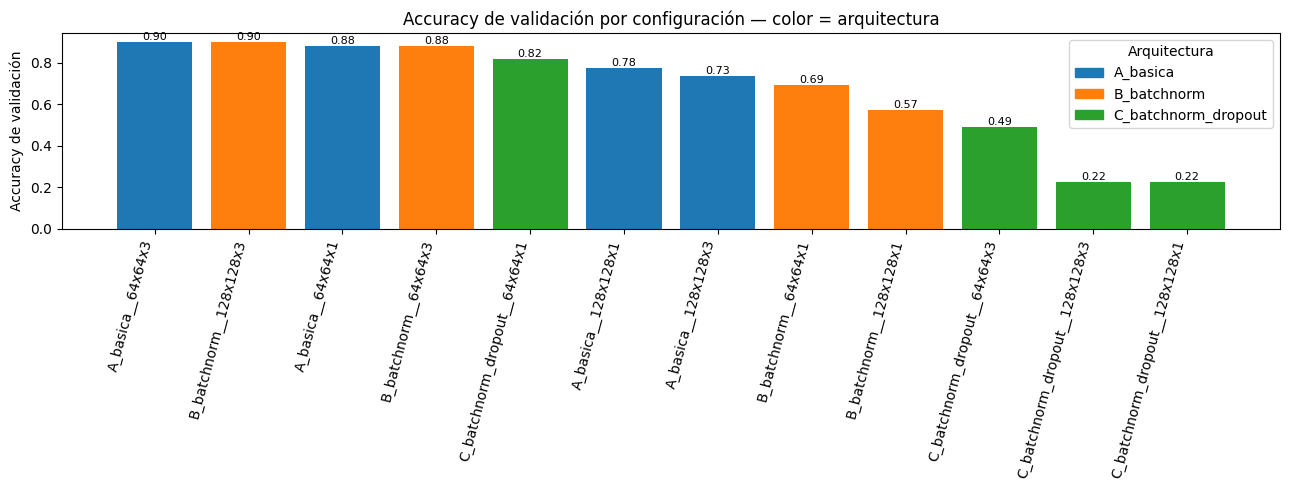

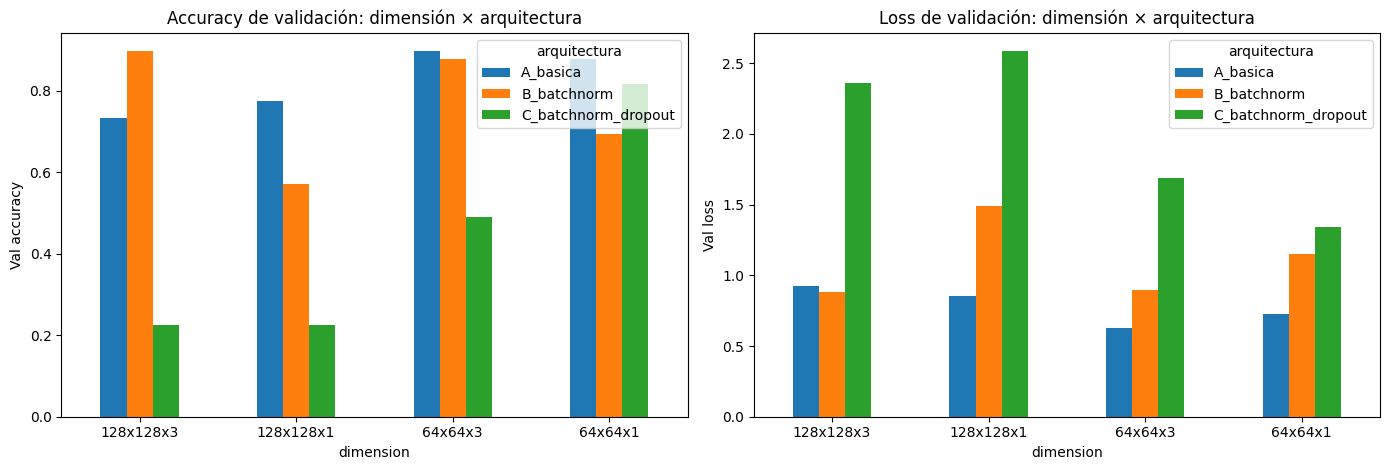

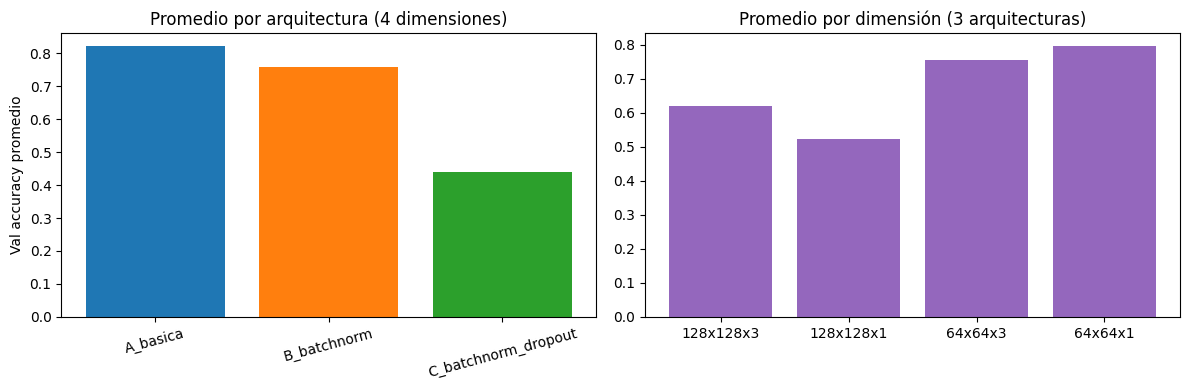

In [12]:
# --- Gráfico 1: val accuracy de las 12 configuraciones (color = arquitectura) ---
COLOR_ARQ = {"A_basica": "#1f77b4", "B_batchnorm": "#ff7f0e", "C_batchnorm_dropout": "#2ca02c"}
orden = df_resultados.sort_values("val_accuracy", ascending=False)

plt.figure(figsize=(13, 5))
barras = plt.bar(orden["configuracion"], orden["val_accuracy"],
                 color=[COLOR_ARQ[a] for a in orden["arquitectura"]])
plt.bar_label(barras, fmt="%.2f", fontsize=8)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Accuracy de validación")
plt.title("Accuracy de validación por configuración — color = arquitectura")
plt.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR_ARQ.values()], COLOR_ARQ.keys(), title="Arquitectura")
plt.tight_layout(); plt.show()

# --- Gráfico 2 y 3: arquitectura x dimensión (accuracy y loss) ---
orden_dim = [nombre_dim(t, c) for t, c in DIMENSIONES]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pivot_acc = df_resultados.pivot(index="dimension", columns="arquitectura", values="val_accuracy").loc[orden_dim]
pivot_acc.plot(kind="bar", ax=axes[0], color=[COLOR_ARQ[c] for c in pivot_acc.columns], rot=0)
axes[0].set_ylabel("Val accuracy"); axes[0].set_title("Accuracy de validación: dimensión × arquitectura")
pivot_loss = df_resultados.pivot(index="dimension", columns="arquitectura", values="val_loss").loc[orden_dim]
pivot_loss.plot(kind="bar", ax=axes[1], color=[COLOR_ARQ[c] for c in pivot_loss.columns], rot=0)
axes[1].set_ylabel("Val loss"); axes[1].set_title("Loss de validación: dimensión × arquitectura")
plt.tight_layout(); plt.show()

# --- Gráfico 4: ¿importó más la arquitectura o la dimensión? ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
por_arq = df_resultados.groupby("arquitectura")["val_accuracy"].mean()
axes[0].bar(por_arq.index, por_arq.values, color=[COLOR_ARQ[a] for a in por_arq.index])
axes[0].set_title("Promedio por arquitectura (4 dimensiones)"); axes[0].set_ylabel("Val accuracy promedio")
axes[0].tick_params(axis="x", rotation=15)
por_dim = df_resultados.groupby("dimension")["val_accuracy"].mean().loc[orden_dim]
axes[1].bar(por_dim.index, por_dim.values, color="#9467bd")
axes[1].set_title("Promedio por dimensión (3 arquitecturas)")
plt.tight_layout(); plt.show()

### Curvas de entrenamiento de las 12 configuraciones (train vs val)
Una fila por arquitectura y una columna por dimensión. Azul = entrenamiento, naranja = validación.
Si `train` sigue bajando y `val` se queda arriba o sube, hay sobreajuste — es lo que la
regularización (BatchNorm + Dropout de la arquitectura C) intenta reducir.

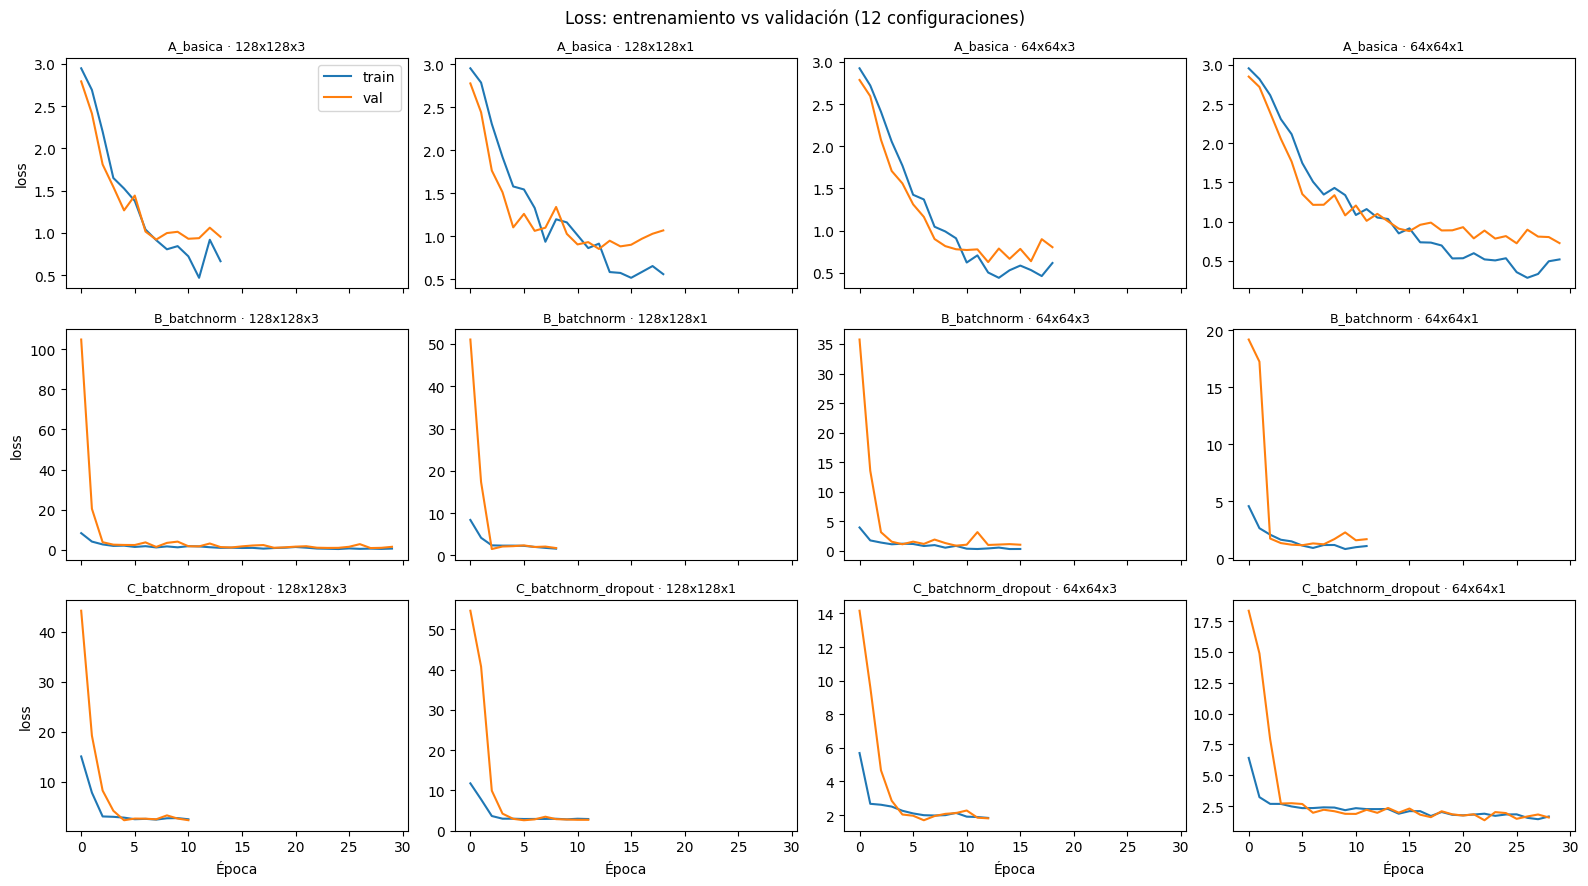

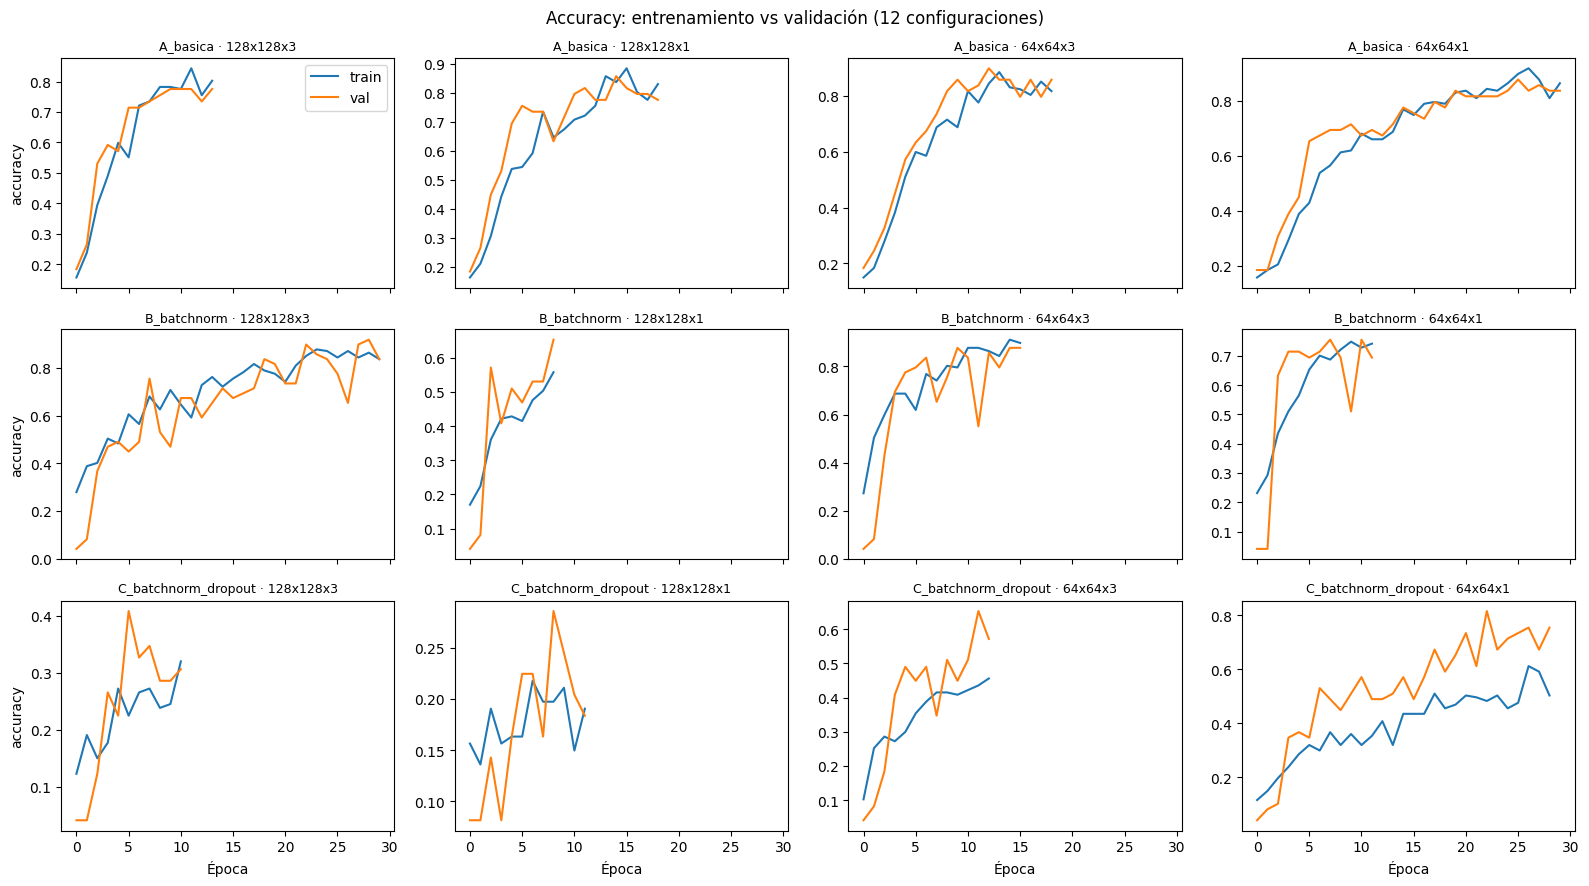

In [13]:
def graficar_curvas(metrica, titulo, nombre_archivo):
    fig, axes = plt.subplots(len(ARQUITECTURAS), len(DIMENSIONES), figsize=(16, 9), sharex=True)
    for i, arq in enumerate(ARQUITECTURAS):
        for j, (tam, canales) in enumerate(DIMENSIONES):
            clave = f"{arq}__{nombre_dim(tam, canales)}"
            h = historiales[clave].history
            ax = axes[i, j]
            ax.plot(h[metrica], label="train")
            ax.plot(h["val_" + metrica], label="val")
            ax.set_title(f"{arq} · {nombre_dim(tam, canales)}", fontsize=9)
            if j == 0: ax.set_ylabel(metrica)
            if i == len(ARQUITECTURAS) - 1: ax.set_xlabel("Época")
            if i == 0 and j == 0: ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=150)
    plt.show()

graficar_curvas("loss", "Loss: entrenamiento vs validación (12 configuraciones)", "curvas_loss_12.png")
graficar_curvas("accuracy", "Accuracy: entrenamiento vs validación (12 configuraciones)", "curvas_accuracy_12.png")

### Selección del modelo ganador
El modelo elegido es el de mayor `val_accuracy` (desempate por menor `val_loss`): la
configuración que mejor generalizó a datos que no vio durante el ajuste de pesos. Este es el
modelo que luego se envuelve en la API. Como el preprocesado de dimensión va dentro del
modelo, el archivo guardado siempre recibe 128×128×3.

In [14]:
mejor_config = df_resultados.iloc[0]["configuracion"]
mejor_arquitectura = mejor_config  # nombre usado en títulos de gráficos
modelo_final = modelos_entrenados[mejor_config]

print(f"Configuración ganadora: {mejor_config}")
print(f"Val accuracy: {df_resultados.iloc[0]['val_accuracy']:.4f}")
print(f"Val loss: {df_resultados.iloc[0]['val_loss']:.4f}")
print(f"Parámetros: {df_resultados.iloc[0]['n_parametros']:,}")
print("Entrada del modelo:", modelo_final.input_shape)

Configuración ganadora: A_basica__64x64x3
Val accuracy: 0.8980
Val loss: 0.6264
Parámetros: 1,144,532
Entrada del modelo: (None, 128, 128, 3)


## 9. Evaluación final en el conjunto de Test (una sola vez, IL 2.4)

In [15]:
test_loss, test_acc = modelo_final.evaluate(x_test, y_test, verbose=0)
print(f"Configuración evaluada: {mejor_config}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

Configuración evaluada: A_basica__64x64x3
Test accuracy: 0.8776
Test loss: 0.3529


In [16]:
probs = modelo_final.predict(x_test, verbose=0)
conf = probs.max(axis=1)
pred = probs.argmax(axis=1)
idx_desc = num_clases - 1
es_desc = (y_test == idx_desc)

print(f"Test: {(~es_desc).sum()} fotos de alumnos, {es_desc.sum()} de desconocidos\n")
print("umbral | alumnos aceptados bien | desconocidos rechazados")
for u in [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]:
    ok_alumnos = ((pred == y_test) & (conf >= u) & ~es_desc).sum() / max((~es_desc).sum(), 1)
    rech_desc = (((pred == idx_desc) | (conf < u)) & es_desc).sum() / max(es_desc.sum(), 1)
    print(f"{u:.2f}   |        {ok_alumnos:.0%}            |        {rech_desc:.0%}")

Test: 40 fotos de alumnos, 9 de desconocidos

umbral | alumnos aceptados bien | desconocidos rechazados
0.50   |        82%            |        89%
0.60   |        80%            |        89%
0.70   |        70%            |        89%
0.75   |        70%            |        89%
0.80   |        70%            |        100%
0.85   |        68%            |        100%
0.90   |        62%            |        100%


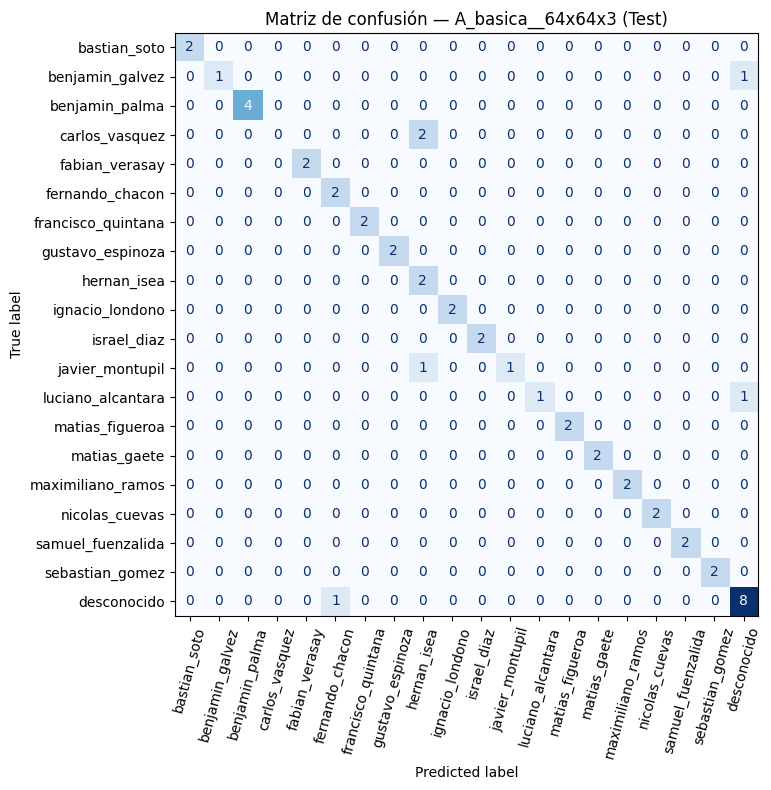

In [17]:
y_pred_probs = modelo_final.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred, labels=range(num_clases))
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)
disp.plot(ax=ax, xticks_rotation=75, colorbar=False, cmap="Blues")
plt.title(f"Matriz de confusión — {mejor_arquitectura} (Test)")
plt.tight_layout()
plt.show()


In [18]:
print("Reporte de clasificación:\n")
print(classification_report(y_test, y_pred, labels=range(num_clases), target_names=clases, zero_division=0))


Reporte de clasificación:

                    precision    recall  f1-score   support

      bastian_soto       1.00      1.00      1.00         2
   benjamin_galvez       1.00      0.50      0.67         2
    benjamin_palma       1.00      1.00      1.00         4
    carlos_vasquez       0.00      0.00      0.00         2
    fabian_verasay       1.00      1.00      1.00         2
   fernando_chacon       0.67      1.00      0.80         2
francisco_quintana       1.00      1.00      1.00         2
  gustavo_espinoza       1.00      1.00      1.00         2
       hernan_isea       0.40      1.00      0.57         2
   ignacio_londono       1.00      1.00      1.00         2
       israel_diaz       1.00      1.00      1.00         2
   javier_montupil       1.00      0.50      0.67         2
 luciano_alcantara       1.00      0.50      0.67         2
   matias_figueroa       1.00      1.00      1.00         2
      matias_gaete       1.00      1.00      1.00         2
 maximiliano

### Evaluación cualitativa: aciertos y errores sobre Test
Se muestran fotos de Test con la clase real, la predicha y la confianza del modelo.
Verde = acierto, rojo = error. Sirve para ver *qué* confunde el modelo y por qué
(pose, iluminación, personas parecidas), algo que las métricas solas no muestran.

Aciertos: 43 | Errores: 6 de 49 fotos de Test


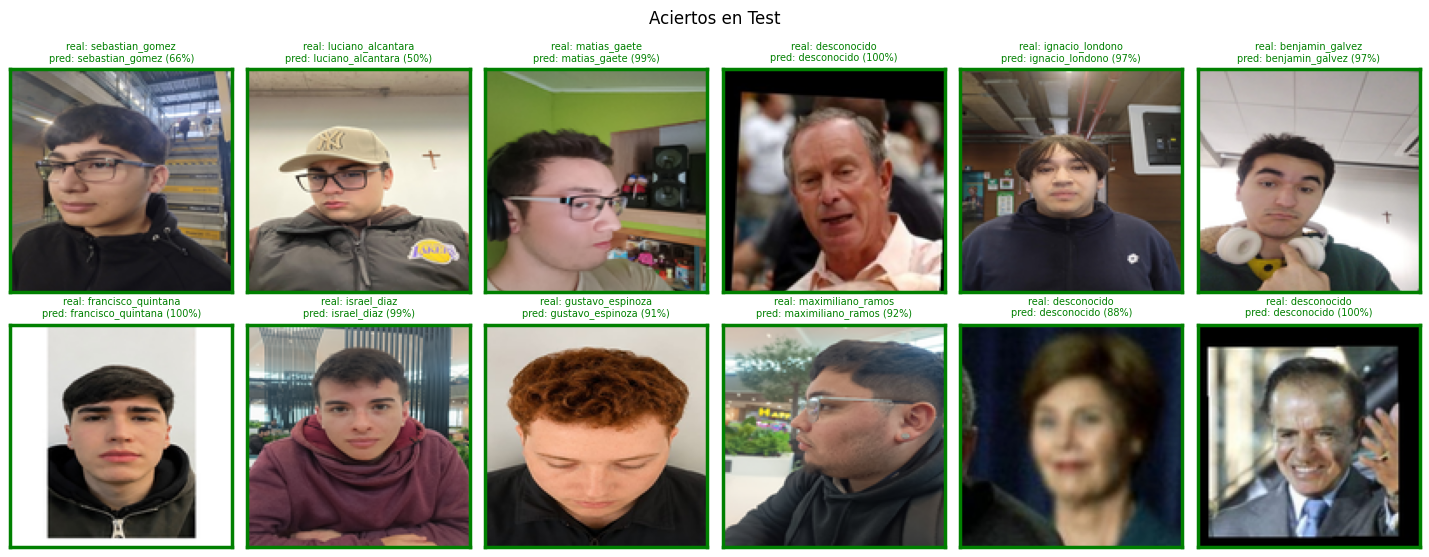

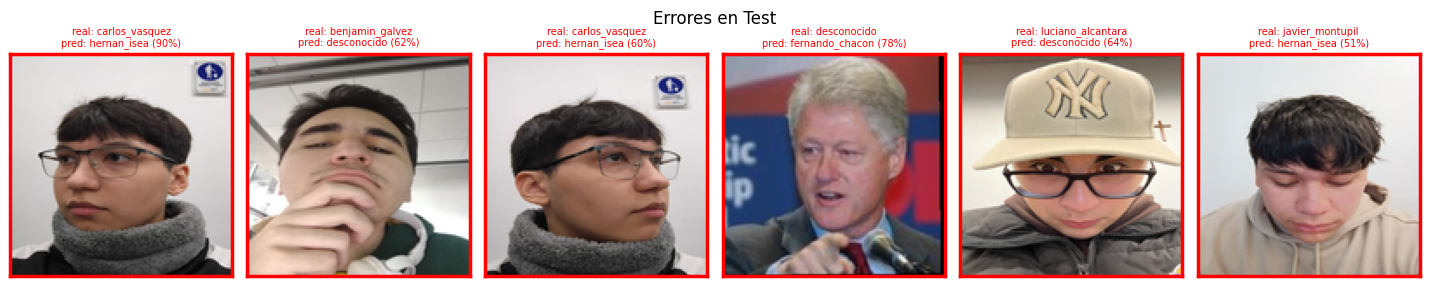

In [19]:
probs_t = modelo_final.predict(x_test, verbose=0)
pred_t = probs_t.argmax(axis=1)
conf_t = probs_t.max(axis=1)
aciertos = np.where(pred_t == y_test)[0]
errores = np.where(pred_t != y_test)[0]
print(f"Aciertos: {len(aciertos)} | Errores: {len(errores)} de {len(y_test)} fotos de Test")

def mosaico(indices, titulo, color, archivo, max_n=12, cols=6):
    indices = indices[:max_n]
    filas = max(1, int(np.ceil(len(indices) / cols)))
    fig, axes = plt.subplots(filas, cols, figsize=(2.4 * cols, 2.9 * filas))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        ax.imshow(x_test[i])
        ax.set_title(f"real: {clases[y_test[i]]}\npred: {clases[pred_t[i]]} ({conf_t[i]:.0%})",
                     fontsize=7, color=color)
        ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor(color); s.set_linewidth(2.5)
    fig.suptitle(titulo)
    plt.tight_layout(); plt.savefig(archivo, dpi=150); plt.show()

rng_m = np.random.default_rng(SEED)
mosaico(rng_m.permutation(aciertos), "Aciertos en Test", "green", "test_aciertos.png")
if len(errores):
    mosaico(errores, "Errores en Test", "red", "test_errores.png")

## 10. Guardar el modelo ganador

Este archivo es el que la **API** del EP2 va a cargar: recibe una imagen
convertida en matriz 128×128×3 (la normalización a [0, 1] la hace la API) y devuelve el
nombre del alumno (o indica que no está en la base). Si la dimensión ganadora es 64×64 o
gris, la conversión ya va dentro del modelo.

In [20]:
modelo_final.save("modelo_cnn_rostros_curso.keras")

import json
with open("clases_cnn_rostros.json", "w", encoding="utf-8") as f:
    json.dump(clases, f, ensure_ascii=False, indent=2)

# Verificación: recargar el archivo tal como lo hará la API y comprobar que predice igual
modelo_recargado = keras.models.load_model("modelo_cnn_rostros_curso.keras")
p1 = modelo_final.predict(x_test[:8], verbose=0)
p2 = modelo_recargado.predict(x_test[:8], verbose=0)
print("Entrada que acepta la API:", modelo_recargado.input_shape)
print("Predicciones idénticas tras recargar:", np.allclose(p1, p2, atol=1e-5))
print(f"Modelo ganador ({mejor_config}) guardado en: modelo_cnn_rostros_curso.keras")
print("Lista de clases guardada en: clases_cnn_rostros.json")

Entrada que acepta la API: (None, 128, 128, 3)
Predicciones idénticas tras recargar: True
Modelo ganador (A_basica__64x64x3) guardado en: modelo_cnn_rostros_curso.keras
Lista de clases guardada en: clases_cnn_rostros.json


## 11. Conclusión

Completar con base en la tabla y los gráficos anteriores:

- **¿Qué configuración (arquitectura × dimensión) ganó y por qué?** ¿Pesó más la
  arquitectura (BatchNorm / Dropout) o la dimensión de la imagen?
- **¿El color (3 canales) marcó diferencia frente a gris (1 canal)?** ¿Y bajar de
  128×128 a 64×64? Relacionarlo con el costo (`n_parametros`, `tiempo_seg`).
- **¿Qué configuraciones muestran sobreajuste en las curvas?** (train muy por debajo de val
  en loss) ¿La regularización de la arquitectura C lo redujo?
- **Ojo con la validación:** val tiene pocas fotos (~50), así que diferencias de 1–2 puntos
  entre configuraciones no son concluyentes; el Test se usa una sola vez al final.
- **¿Qué alumno/clase confunde más el modelo?** (matriz de confusión y mosaico de errores)
  ¿Se debe a pocas fotos, poses o personas parecidas?
- **Umbral de confianza:** a partir de la tabla de calibración, justificar el umbral que usa
  la API (0.50) para responder "no está en la base de datos".
- **Limitación principal:** tamaño y diversidad de la base de datos.

### Siguiente paso
Copiar `modelo_cnn_rostros_curso.keras` y `clases_cnn_rostros.json` a la carpeta de la API,
reiniciar `uvicorn` y probar con la app (APK).

In [21]:
from google.colab import files
files.download("modelo_cnn_rostros_curso.keras")
files.download("clases_cnn_rostros.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>